In [2]:
%%time
%%capture captured_output
%pip install numpy==1.26 matplotlib==3.9.2 tensorflow==2.19
%pip install torch==2.8.0+cpu torchvision==0.23.0+cpu torchaudio==2.8.0+cpu \
    --index-url https://download.pytorch.org/whl/cpu

CPU times: user 4.57 ms, sys: 13.3 ms, total: 17.9 ms
Wall time: 1.51 s


In [3]:
txt_output = captured_output.stdout
txt_split = txt_output.splitlines()

t = ['error' if any('error' in x for x in txt_split) else 'sucess']

print(t)


['sucess']


In [4]:
import os
import skillsnetwork
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

2026-10-28 15:33:52.507666: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-28 15:33:52.508268: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-28 15:33:52.510896: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-28 15:33:52.518577: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793216032.536272   40268 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793216032.54

In [5]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/4Z1fwRR295-1O3PMQBH6Dg/images-dataSAT.tar"
await skillsnetwork.prepare(url=url, path='.', overwrite=True)

  0%|          | 0/6003 [00:00<?, ?it/s]

Saved to '.'


In [6]:
base_dir = './images_dataSAT/'
non_agri = os.path.join(base_dir, 'class_0_non_agri')
one_agri = os.path.join(base_dir, 'class_1_agri')


In [7]:
IMAGE_SIZE = (64,64)
BATCH_SIZE = 10

train_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed=1337,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

for images, labels in train_ds.take(5):
    print(labels)



Found 6000 files belonging to 2 classes.
Using 1200 files for validation.
tf.Tensor([1 1 1 0 1 1 0 1 1 1], shape=(10,), dtype=int32)
tf.Tensor([1 0 1 1 0 1 0 0 1 1], shape=(10,), dtype=int32)
tf.Tensor([1 0 1 1 0 0 0 0 1 0], shape=(10,), dtype=int32)
tf.Tensor([1 0 1 1 0 0 0 1 0 0], shape=(10,), dtype=int32)
tf.Tensor([1 1 1 1 1 0 1 1 1 0], shape=(10,), dtype=int32)


E0000 00:00:1793216043.025238   40268 cuda_executor.cc:1228] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793216043.100144   40268 gpu_device.cc:2341] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
2026-10-28 15:34:03.204419: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [8]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed = 1337,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

for images, labels in val_ds.take(5):
    print(labels)

Found 6000 files belonging to 2 classes.
Using 1200 files for validation.
tf.Tensor([1 1 1 0 1 1 0 1 1 1], shape=(10,), dtype=int32)
tf.Tensor([1 0 1 1 0 1 0 0 1 1], shape=(10,), dtype=int32)
tf.Tensor([1 0 1 1 0 0 0 0 1 0], shape=(10,), dtype=int32)
tf.Tensor([1 0 1 1 0 0 0 1 0 0], shape=(10,), dtype=int32)
tf.Tensor([1 1 1 1 1 0 1 1 1 0], shape=(10,), dtype=int32)


2026-10-28 15:34:09.563110: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Class name inferred by keras: ['class_0_non_agri', 'class_1_agri']


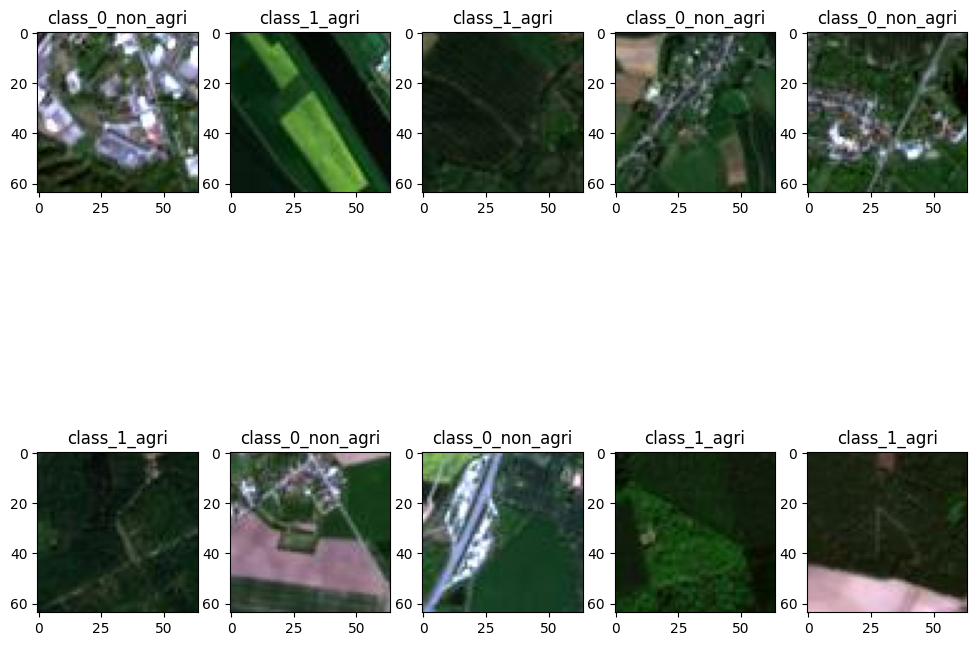

In [11]:
print(f"Class name inferred by keras: {train_ds.class_names}")

plt.figure(figsize=(12,10))
for images, labels in train_ds.take(1):
    for i in range(BATCH_SIZE):
        ax = plt.subplot(2,5, i+1)
        plt.imshow(images[i] / 255)
        plt.title(train_ds.class_names[labels[i]])
    plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(0.2)
])

train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
print(train_ds)
print(val_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
